# Machine Learning Assignment 2
## Classification Models and Performance Evaluation

**Course:** M.Tech Artificial Intelligence and Machine Learning  
**Institute:** BITS Pilani

### Problem Statement

The objective of this assignment is to implement and evaluate multiple machine learning classification algorithms using a real-world dataset.

The assignment involves data exploration, preprocessing, model training, performance evaluation, and comparison of different classification algorithms.

### Dataset
Adult Income Classification Dataset (UCI Machine Learning Repository)

### Classification Models
1. Logistic Regression
2. Decision Tree Classifier
3. K-Nearest Neighbors (KNN)
4. Gaussian Naive Bayes
5. Random Forest Classifier

### Evaluation Metrics
- Accuracy
- AUC Score
- Precision
- Recall
- F1 Score
- Matthews Correlation Coefficient (MCC)

In [374]:
# Import required libraries

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')

# Display configuration
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)

# Visualization settings
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

print("All libraries imported successfully!")
print("NumPy version:", np.__version__)
print("Pandas version:", pd.__version__)

All libraries imported successfully!
NumPy version: 2.5.2
Pandas version: 2.3.3


In [375]:
# Load the Adult Income Classification Dataset

from sklearn.datasets import fetch_openml

# Download dataset
adult_data = fetch_openml(
    name='adult',
    version=2,
    as_frame=True
)

# Convert into a Pandas DataFrame
df = adult_data.frame.copy()

# Rename target column
target_column = adult_data.target.name
df.rename(columns={target_column: 'income'}, inplace=True)

# Display dataset information
print("Dataset loaded successfully!")
print("-" * 50)

print("Dataset Shape:", df.shape)
print("Number of Records:", df.shape[0])
print("Number of Features:", df.shape[1] - 1)
print("Target Variable: income")

# Display first five records
display(df.head())

Dataset loaded successfully!
--------------------------------------------------
Dataset Shape: (48842, 15)
Number of Records: 48842
Number of Features: 14
Target Variable: income


,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,25,Private,226802,11th,7,Never-married,Machine-op-inspct,Own-child,Black,Male,0,0,40,United-States,<=50K
1,38,Private,89814,HS-grad,9,Married-civ-spouse,Farming-fishing,Husband,White,Male,0,0,50,United-States,<=50K
2,28,Local-gov,336951,Assoc-acdm,12,Married-civ-spouse,Protective-serv,Husband,White,Male,0,0,40,United-States,>50K
3,44,Private,160323,Some-college,10,Married-civ-spouse,Machine-op-inspct,Husband,Black,Male,7688,0,40,United-States,>50K
4,18,NaN,103497,Some-college,10,Never-married,NaN,Own-child,White,Female,0,0,30,United-States,<=50K


In [376]:
# Understand dataset structure and data types

print("DATASET INFORMATION")
print("=" * 60)

df.info()

print("\n\nDATA TYPES OF FEATURES")
print("=" * 60)

display(df.dtypes.to_frame(name="Data Type"))

print("\n\nSTATISTICAL SUMMARY")
print("=" * 60)

display(df.describe(include="all").T)

DATASET INFORMATION
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48842 entries, 0 to 48841
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype   
---  ------          --------------  -----   
 0   age             48842 non-null  int64   
 1   workclass       46043 non-null  category
 2   fnlwgt          48842 non-null  int64   
 3   education       48842 non-null  category
 4   education-num   48842 non-null  int64   
 5   marital-status  48842 non-null  category
 6   occupation      46033 non-null  category
 7   relationship    48842 non-null  category
 8   race            48842 non-null  category
 9   sex             48842 non-null  category
 10  capital-gain    48842 non-null  int64   
 11  capital-loss    48842 non-null  int64   
 12  hours-per-week  48842 non-null  int64   
 13  native-country  47985 non-null  category
 14  income          48842 non-null  category
dtypes: category(9), int64(6)
memory usage: 2.7 MB


DATA TYPES OF FEATURES


,Data Type
age,int64
workclass,category
fnlwgt,int64
education,category
education-num,int64
marital-status,category
occupation,category
relationship,category
race,category
sex,category




STATISTICAL SUMMARY


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
age,48842.0,NaN,NaN,NaN,38.643585,13.71051,17.0,28.0,37.0,48.0,90.0
workclass,46043,8,Private,33906,NaN,NaN,NaN,NaN,NaN,NaN,NaN
fnlwgt,48842.0,NaN,NaN,NaN,189664.134597,105604.025423,12285.0,117550.5,178144.5,237642.0,1490400.0
education,48842,16,HS-grad,15784,NaN,NaN,NaN,NaN,NaN,NaN,NaN
education-num,48842.0,NaN,NaN,NaN,10.078089,2.570973,1.0,9.0,10.0,12.0,16.0
marital-status,48842,7,Married-civ-spouse,22379,NaN,NaN,NaN,NaN,NaN,NaN,NaN
occupation,46033,14,Prof-specialty,6172,NaN,NaN,NaN,NaN,NaN,NaN,NaN
relationship,48842,6,Husband,19716,NaN,NaN,NaN,NaN,NaN,NaN,NaN
race,48842,5,White,41762,NaN,NaN,NaN,NaN,NaN,NaN,NaN
sex,48842,2,Male,32650,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [377]:
# Identify missing values and duplicate records

print("MISSING VALUE ANALYSIS")
print("=" * 60)

missing_values = df.isnull().sum()

missing_percentage = (missing_values / len(df)) * 100

missing_summary = pd.DataFrame({
    'Missing Values': missing_values,
    'Missing Percentage': missing_percentage
})

display(missing_summary[missing_summary['Missing Values'] > 0])

print("\nTotal Missing Values:", missing_values.sum())

print("\nDUPLICATE RECORD ANALYSIS")
print("=" * 60)

duplicate_count = df.duplicated().sum()

print("Total Duplicate Records:", duplicate_count)
print("Percentage of Duplicates:", round(
    (duplicate_count / len(df)) * 100, 2
), "%")

MISSING VALUE ANALYSIS


,Missing Values,Missing Percentage
workclass,2799,5.730724
occupation,2809,5.751198
native-country,857,1.754637



Total Missing Values: 6465

DUPLICATE RECORD ANALYSIS
Total Duplicate Records: 52
Percentage of Duplicates: 0.11 %


INCOME CLASS DISTRIBUTION


,Count,Percentage
income,,
<=50K,37155,76.071823
>50K,11687,23.928177


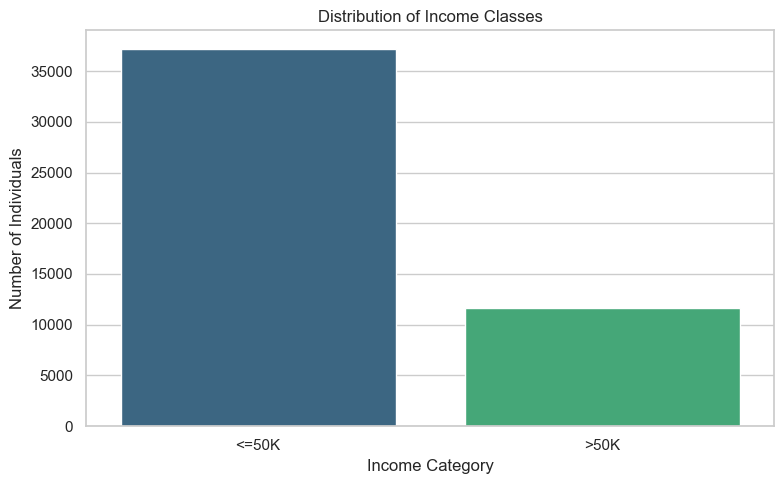

In [378]:
# Analyze target variable distribution

print("INCOME CLASS DISTRIBUTION")
print("=" * 50)

income_counts = df['income'].value_counts()

income_percentage = df['income'].value_counts(normalize=True) * 100

class_distribution = pd.DataFrame({
    'Count': income_counts,
    'Percentage': income_percentage
})

display(class_distribution)

# Visualize class distribution

plt.figure(figsize=(8, 5))

sns.countplot(
    data=df,
    x='income',
    hue='income',
    palette='viridis',
    legend=False
)

plt.title('Distribution of Income Classes')
plt.xlabel('Income Category')
plt.ylabel('Number of Individuals')
plt.tight_layout()
plt.show()

In [379]:
# Remove duplicate records

df_clean = df.drop_duplicates().copy()

print("DATA CLEANING SUMMARY")
print("=" * 50)

print("Original dataset shape:", df.shape)
print("Dataset shape after removing duplicates:", df_clean.shape)
print("Duplicates removed:", df.shape[0] - df_clean.shape[0])

# Separate features and target variable

X = df_clean.drop(columns=['income'])

y = df_clean['income'].map({
    '<=50K': 0,
    '>50K': 1
})

print("\nFEATURES AND TARGET")
print("=" * 50)

print("Feature matrix shape:", X.shape)
print("Target variable shape:", y.shape)

print("\nTarget encoding:")
print("<=50K = 0")
print(">50K = 1")

print("\nTarget distribution:")
display(y.value_counts())

DATA CLEANING SUMMARY
Original dataset shape: (48842, 15)
Dataset shape after removing duplicates: (48790, 15)
Duplicates removed: 52

FEATURES AND TARGET
Feature matrix shape: (48790, 14)
Target variable shape: (48790,)

Target encoding:
<=50K = 0
>50K = 1

Target distribution:


income
0    37109
1    11681
Name: count, dtype: int64

In [380]:
# Split dataset into training and testing sets

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Display dataset split information

print("TRAIN-TEST SPLIT SUMMARY")
print("=" * 50)

print("Original dataset:", X.shape)
print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining target distribution:")
display(y_train.value_counts(normalize=True) * 100)

print("\nTesting target distribution:")
display(y_test.value_counts(normalize=True) * 100)

print("\nRandom State: 42")
print("Training Size: 80%")
print("Testing Size: 20%")

TRAIN-TEST SPLIT SUMMARY
Original dataset: (48790, 14)
Training features: (39032, 14)
Testing features: (9758, 14)

Training target distribution:


income
0    76.058106
1    23.941894
Name: proportion, dtype: float64


Testing target distribution:


income
0    76.060668
1    23.939332
Name: proportion, dtype: float64


Random State: 42
Training Size: 80%
Testing Size: 20%


In [381]:
# Import preprocessing libraries

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer

# Identify numerical and categorical columns

numerical_features = X_train.select_dtypes(
    include=['int64', 'float64']
).columns.tolist()

categorical_features = X_train.select_dtypes(
    include=['object', 'category']
).columns.tolist()

print("Numerical Features:", numerical_features)
print("\nCategorical Features:", categorical_features)

# Numerical preprocessing pipeline

numerical_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# Categorical preprocessing pipeline

categorical_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

# Combine both preprocessing pipelines

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numerical_pipeline, numerical_features),
        ('cat', categorical_pipeline, categorical_features)
    ]
)

print("\nPreprocessing pipeline created successfully!")

Numerical Features: ['age', 'fnlwgt', 'education-num', 'capital-gain', 'capital-loss', 'hours-per-week']

Categorical Features: ['workclass', 'education', 'marital-status', 'occupation', 'relationship', 'race', 'sex', 'native-country']

Preprocessing pipeline created successfully!


In [382]:
# Apply preprocessing to training and testing datasets

# Fit preprocessing only on training data
X_train_processed = preprocessor.fit_transform(X_train)

# Transform testing data using the fitted preprocessor
X_test_processed = preprocessor.transform(X_test)

# Display processed dataset information

print("PREPROCESSING COMPLETED")
print("=" * 50)

print("Original training shape:", X_train.shape)
print("Processed training shape:", X_train_processed.shape)

print("\nOriginal testing shape:", X_test.shape)
print("Processed testing shape:", X_test_processed.shape)

print("\nMissing values after preprocessing:",
      np.isnan(X_train_processed.toarray() if hasattr(X_train_processed, "toarray")
               else X_train_processed).sum())

print("\nAll preprocessing steps completed successfully!")

PREPROCESSING COMPLETED
Original training shape: (39032, 14)
Processed training shape: (39032, 105)

Original testing shape: (9758, 14)
Processed testing shape: (9758, 105)

Missing values after preprocessing: 0

All preprocessing steps completed successfully!


In [383]:
# Import classification algorithms

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import RandomForestClassifier

# Import evaluation metrics

from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef,
    confusion_matrix,
    classification_report
)

print("All five classification models imported successfully!")
print("All six evaluation metrics imported successfully!")

All five classification models imported successfully!
All six evaluation metrics imported successfully!


In [384]:
# Initialize all five classification models

models = {
    'Logistic Regression': LogisticRegression(
        max_iter=1000,
        random_state=42
    ),

    'Decision Tree': DecisionTreeClassifier(
        random_state=42
    ),

    'K-Nearest Neighbors': KNeighborsClassifier(
        n_neighbors=5
    ),

    'Gaussian Naive Bayes': GaussianNB(),

    'Random Forest': RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    )
}

print("CLASSIFICATION MODELS CONFIGURED")
print("=" * 50)

for model_name, model in models.items():
    print(f"{model_name}: {model}")

print("\nTotal models configured:", len(models))

CLASSIFICATION MODELS CONFIGURED
Logistic Regression: LogisticRegression(max_iter=1000, random_state=42)
Decision Tree: DecisionTreeClassifier(random_state=42)
K-Nearest Neighbors: KNeighborsClassifier()
Gaussian Naive Bayes: GaussianNB()
Random Forest: RandomForestClassifier(n_jobs=-1, random_state=42)

Total models configured: 5


In [385]:
# Convert sparse matrices into dense NumPy arrays

X_train_dense = (
    X_train_processed.toarray()
    if hasattr(X_train_processed, "toarray")
    else X_train_processed
)

X_test_dense = (
    X_test_processed.toarray()
    if hasattr(X_test_processed, "toarray")
    else X_test_processed
)

print("DATA CONVERSION COMPLETED")
print("=" * 50)

print("Training data shape:", X_train_dense.shape)
print("Testing data shape:", X_test_dense.shape)

print("Training data type:", type(X_train_dense))
print("Testing data type:", type(X_test_dense))

print("\nData is ready for model training!")

DATA CONVERSION COMPLETED
Training data shape: (39032, 105)
Testing data shape: (9758, 105)
Training data type: <class 'numpy.ndarray'>
Testing data type: <class 'numpy.ndarray'>

Data is ready for model training!


In [386]:
# Train all five classification models

import time

trained_models = {}
training_times = {}

print("MODEL TRAINING STARTED")
print("=" * 60)

for model_name, model in models.items():

    print(f"\nTraining: {model_name}")

    start_time = time.time()

    # Train the model
    model.fit(X_train_dense, y_train)

    end_time = time.time()

    # Store trained model and execution time
    trained_models[model_name] = model
    training_times[model_name] = round(end_time - start_time, 3)

    print(f"Completed: {model_name}")
    print(f"Training time: {training_times[model_name]} seconds")

print("\n" + "=" * 60)
print("ALL FIVE MODELS TRAINED SUCCESSFULLY!")

MODEL TRAINING STARTED

Training: Logistic Regression
Completed: Logistic Regression
Training time: 1.584 seconds

Training: Decision Tree
Completed: Decision Tree
Training time: 0.445 seconds

Training: K-Nearest Neighbors
Completed: K-Nearest Neighbors
Training time: 0.002 seconds

Training: Gaussian Naive Bayes
Completed: Gaussian Naive Bayes
Training time: 0.022 seconds

Training: Random Forest
Completed: Random Forest
Training time: 1.005 seconds

ALL FIVE MODELS TRAINED SUCCESSFULLY!


In [387]:
# Generate predictions using all trained models

predictions = {}
prediction_probabilities = {}

print("GENERATING MODEL PREDICTIONS")
print("=" * 60)

for model_name, model in trained_models.items():

    # Predict class labels
    y_pred = model.predict(X_test_dense)

    # Predict probability of positive class
    y_prob = model.predict_proba(X_test_dense)[:, 1]

    predictions[model_name] = y_pred
    prediction_probabilities[model_name] = y_prob

    print(f"{model_name}: Predictions generated successfully")

print("\n" + "=" * 60)
print("ALL FIVE MODELS GENERATED PREDICTIONS!")

GENERATING MODEL PREDICTIONS
Logistic Regression: Predictions generated successfully
Decision Tree: Predictions generated successfully
K-Nearest Neighbors: Predictions generated successfully
Gaussian Naive Bayes: Predictions generated successfully
Random Forest: Predictions generated successfully

ALL FIVE MODELS GENERATED PREDICTIONS!


In [388]:
# Calculate evaluation metrics for all five models

results = []

print("MODEL PERFORMANCE EVALUATION")
print("=" * 70)

for model_name in trained_models:

    # Get actual and predicted values
    y_pred = predictions[model_name]
    y_prob = prediction_probabilities[model_name]

    # Calculate six evaluation metrics
    accuracy = accuracy_score(y_test, y_pred)
    auc = roc_auc_score(y_test, y_prob)
    precision = precision_score(y_test, y_pred, zero_division=0)
    recall = recall_score(y_test, y_pred, zero_division=0)
    f1 = f1_score(y_test, y_pred, zero_division=0)
    mcc = matthews_corrcoef(y_test, y_pred)

    # Store results
    results.append({
        'Model': model_name,
        'Accuracy': accuracy,
        'AUC': auc,
        'Precision': precision,
        'Recall': recall,
        'F1 Score': f1,
        'MCC': mcc
    })

# Create comparison DataFrame
results_df = pd.DataFrame(results)

# Display results
print("\nMODEL COMPARISON TABLE")
print("=" * 70)

display(
    results_df.style.format({
        'Accuracy': '{:.4f}',
        'AUC': '{:.4f}',
        'Precision': '{:.4f}',
        'Recall': '{:.4f}',
        'F1 Score': '{:.4f}',
        'MCC': '{:.4f}'
    })
)

MODEL PERFORMANCE EVALUATION

MODEL COMPARISON TABLE


,Model,Accuracy,AUC,Precision,Recall,F1 Score,MCC
0,Logistic Regression,0.8477,0.9020,0.7258,0.5848,0.6477,0.5572
1,Decision Tree,0.8082,0.7430,0.5957,0.6182,0.6067,0.4801
2,K-Nearest Neighbors,0.8315,0.8558,0.6624,0.6040,0.6319,0.5239
3,Gaussian Naive Bayes,0.6173,0.8329,0.3777,0.9242,0.5363,0.3855
4,Random Forest,0.8519,0.8995,0.7164,0.6314,0.6712,0.5781


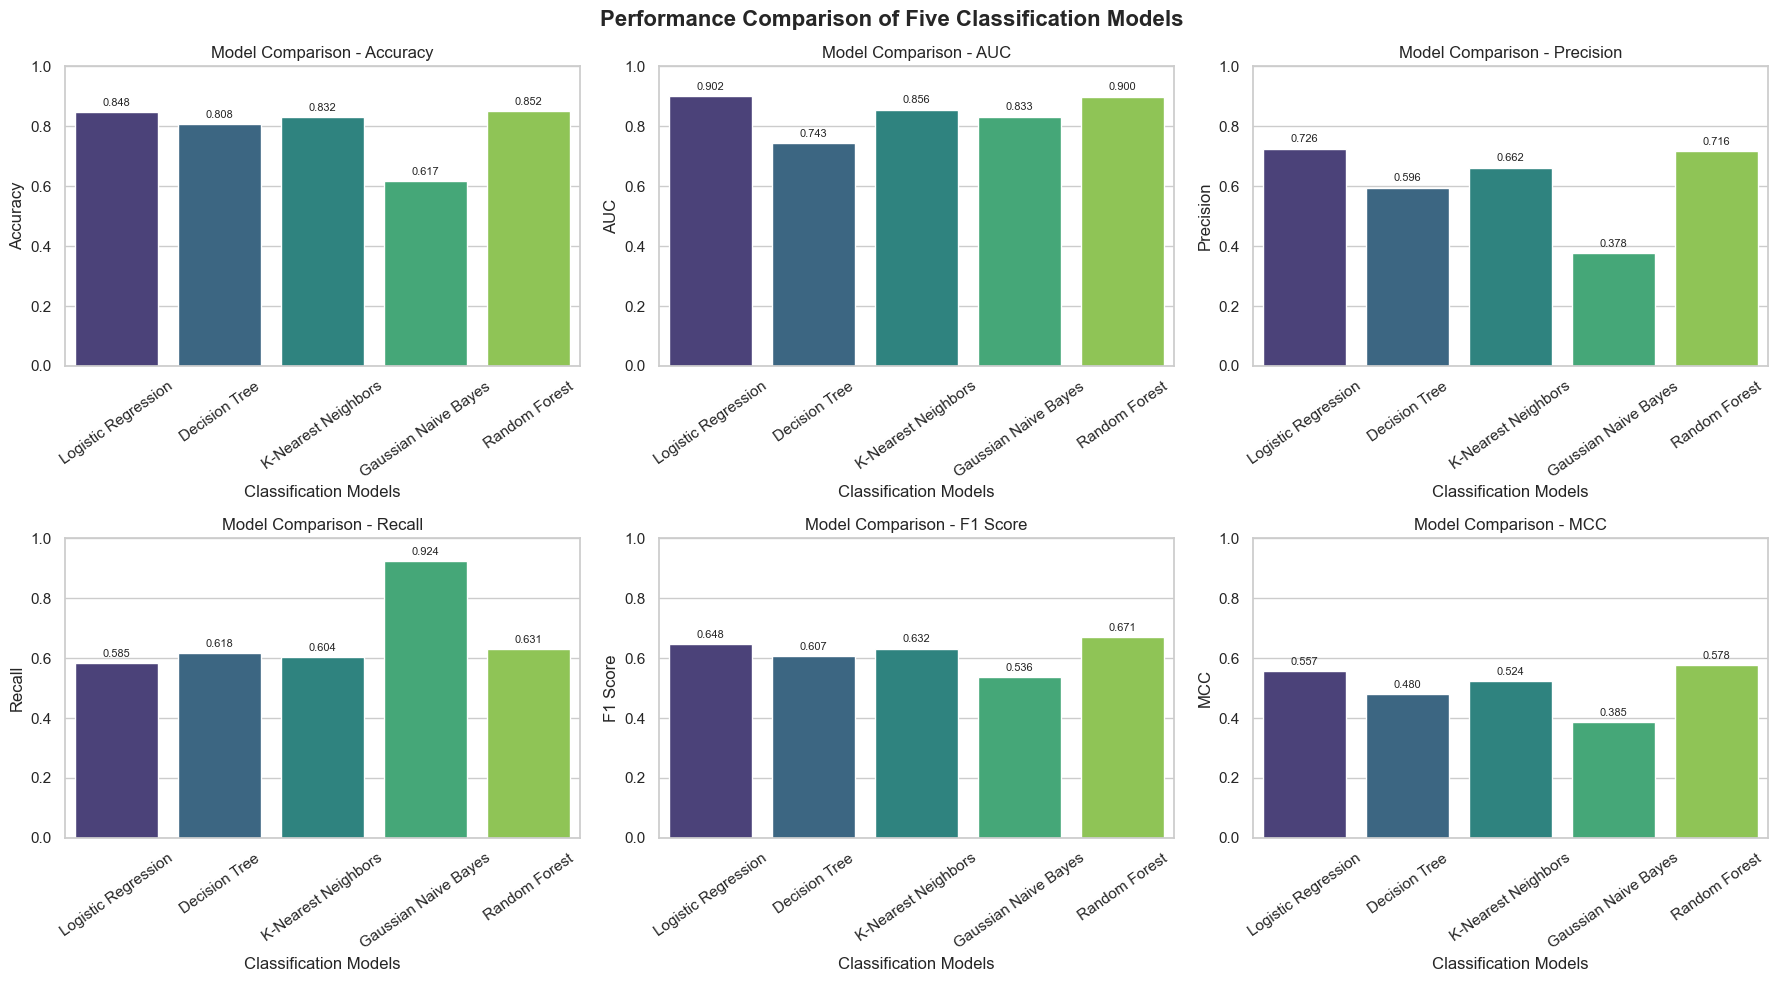

In [389]:
# Visual comparison of all six evaluation metrics

metrics = [
    'Accuracy',
    'AUC',
    'Precision',
    'Recall',
    'F1 Score',
    'MCC'
]

fig, axes = plt.subplots(2, 3, figsize=(18, 10))

axes = axes.flatten()

for i, metric in enumerate(metrics):

    sns.barplot(
        data=results_df,
        x='Model',
        y=metric,
        hue='Model',
        palette='viridis',
        legend=False,
        ax=axes[i]
    )

    axes[i].set_title(f'Model Comparison - {metric}')
    axes[i].set_xlabel('Classification Models')
    axes[i].set_ylabel(metric)

    axes[i].tick_params(axis='x', rotation=35)

    axes[i].set_ylim(0, 1)

    # Display metric values above bars
    for container in axes[i].containers:
        axes[i].bar_label(
            container,
            fmt='%.3f',
            padding=3,
            fontsize=8
        )

plt.suptitle(
    'Performance Comparison of Five Classification Models',
    fontsize=16,
    fontweight='bold'
)

plt.tight_layout()
plt.show()

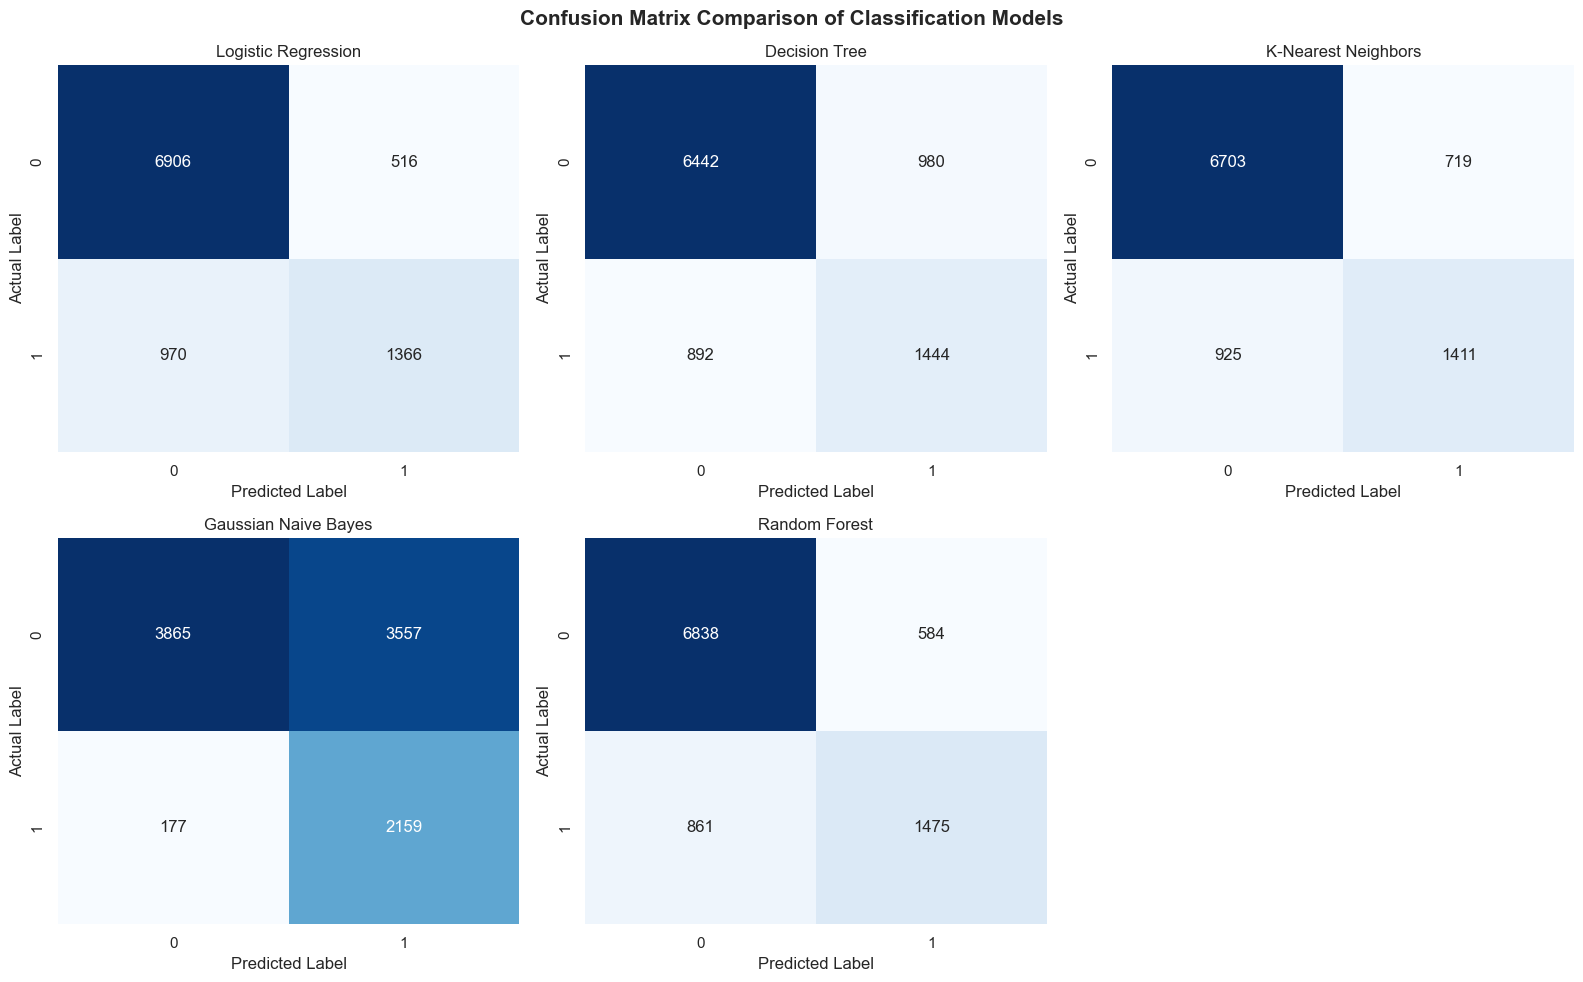

In [390]:
# Generate confusion matrices for all five models

fig, axes = plt.subplots(2, 3, figsize=(16, 10))

axes = axes.flatten()

for i, model_name in enumerate(trained_models):

    cm = confusion_matrix(
        y_test,
        predictions[model_name]
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Blues',
        cbar=False,
        ax=axes[i]
    )

    axes[i].set_title(model_name)
    axes[i].set_xlabel('Predicted Label')
    axes[i].set_ylabel('Actual Label')

# Remove unused sixth subplot
fig.delaxes(axes[5])

plt.suptitle(
    'Confusion Matrix Comparison of Classification Models',
    fontsize=15,
    fontweight='bold'
)

plt.tight_layout()
plt.show()

In [391]:
# Detailed Classification Reports

print("DETAILED CLASSIFICATION REPORTS")
print("=" * 70)

for model_name in trained_models:

    print(f"\nMODEL: {model_name}")
    print("-" * 70)

    report = classification_report(
        y_test,
        predictions[model_name],
        target_names=['Income <=50K', 'Income >50K']
    )

    print(report)

DETAILED CLASSIFICATION REPORTS

MODEL: Logistic Regression
----------------------------------------------------------------------
              precision    recall  f1-score   support

Income <=50K       0.88      0.93      0.90      7422
 Income >50K       0.73      0.58      0.65      2336

    accuracy                           0.85      9758
   macro avg       0.80      0.76      0.78      9758
weighted avg       0.84      0.85      0.84      9758


MODEL: Decision Tree
----------------------------------------------------------------------
              precision    recall  f1-score   support

Income <=50K       0.88      0.87      0.87      7422
 Income >50K       0.60      0.62      0.61      2336

    accuracy                           0.81      9758
   macro avg       0.74      0.74      0.74      9758
weighted avg       0.81      0.81      0.81      9758


MODEL: K-Nearest Neighbors
----------------------------------------------------------------------
              precision

In [392]:
# Display classification reports separately

for model_name in trained_models:

    print("\n" + "=" * 70)
    print(f"CLASSIFICATION REPORT: {model_name}")
    print("=" * 70)

    report_dict = classification_report(
        y_test,
        predictions[model_name],
        target_names=['Income <=50K', 'Income >50K'],
        output_dict=True
    )

    report_df = pd.DataFrame(report_dict).T

    display(report_df.round(4))


CLASSIFICATION REPORT: Logistic Regression


,precision,recall,f1-score,support
Income <=50K,0.8768,0.9305,0.9029,7422.0000
Income >50K,0.7258,0.5848,0.6477,2336.0000
accuracy,0.8477,0.8477,0.8477,0.8477
macro avg,0.8013,0.7576,0.7753,9758.0000
weighted avg,0.8407,0.8477,0.8418,9758.0000



CLASSIFICATION REPORT: Decision Tree


,precision,recall,f1-score,support
Income <=50K,0.8784,0.8680,0.8731,7422.0000
Income >50K,0.5957,0.6182,0.6067,2336.0000
accuracy,0.8082,0.8082,0.8082,0.8082
macro avg,0.7370,0.7431,0.7399,9758.0000
weighted avg,0.8107,0.8082,0.8094,9758.0000



CLASSIFICATION REPORT: K-Nearest Neighbors


,precision,recall,f1-score,support
Income <=50K,0.8787,0.9031,0.8908,7422.0000
Income >50K,0.6624,0.6040,0.6319,2336.0000
accuracy,0.8315,0.8315,0.8315,0.8315
macro avg,0.7706,0.7536,0.7613,9758.0000
weighted avg,0.8270,0.8315,0.8288,9758.0000



CLASSIFICATION REPORT: Gaussian Naive Bayes


,precision,recall,f1-score,support
Income <=50K,0.9562,0.5207,0.6743,7422.0000
Income >50K,0.3777,0.9242,0.5363,2336.0000
accuracy,0.6173,0.6173,0.6173,0.6173
macro avg,0.6670,0.7225,0.6053,9758.0000
weighted avg,0.8177,0.6173,0.6412,9758.0000



CLASSIFICATION REPORT: Random Forest


,precision,recall,f1-score,support
Income <=50K,0.8882,0.9213,0.9044,7422.0000
Income >50K,0.7164,0.6314,0.6712,2336.0000
accuracy,0.8519,0.8519,0.8519,0.8519
macro avg,0.8023,0.7764,0.7878,9758.0000
weighted avg,0.8470,0.8519,0.8486,9758.0000


In [393]:
from sklearn.metrics import roc_curve

print("ROC curve function imported successfully!")

ROC curve function imported successfully!


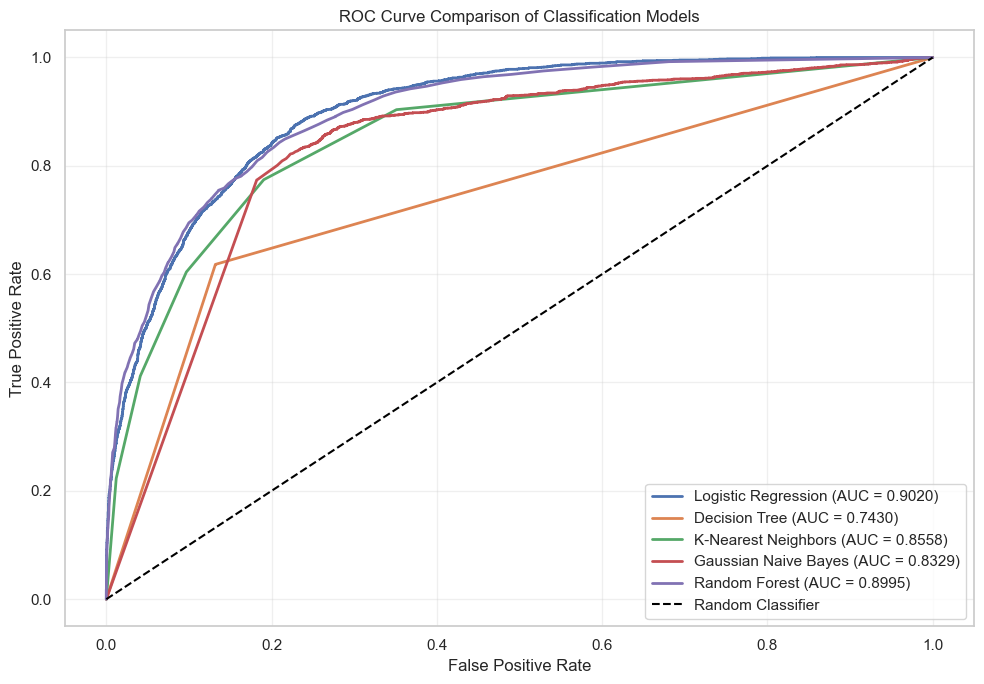

In [394]:
# ROC Curve Comparison of Five Classification Models

plt.figure(figsize=(10, 7))

for model_name in trained_models:

    fpr, tpr, thresholds = roc_curve(
        y_test,
        prediction_probabilities[model_name]
    )

    auc_value = roc_auc_score(
        y_test,
        prediction_probabilities[model_name]
    )

    plt.plot(
        fpr,
        tpr,
        linewidth=2,
        label=f'{model_name} (AUC = {auc_value:.4f})'
    )

# Random classifier reference line
plt.plot(
    [0, 1],
    [0, 1],
    linestyle='--',
    color='black',
    label='Random Classifier'
)

plt.title('ROC Curve Comparison of Classification Models')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')

plt.legend(loc='lower right')
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [395]:
# Final Model Performance Comparison

comparison = results_df.copy()

metrics = [
    'Accuracy',
    'AUC',
    'Precision',
    'Recall',
    'F1 Score',
    'MCC'
]

print("FINAL MODEL PERFORMANCE COMPARISON")
print("=" * 80)

display(comparison.round(4))

print("\nBEST MODEL FOR EACH EVALUATION METRIC")
print("=" * 80)

for metric in metrics:

    best_index = comparison[metric].idxmax()

    best_model = comparison.loc[best_index, 'Model']

    best_score = comparison.loc[best_index, metric]

    print(f"{metric}: {best_model} ({best_score:.4f})")

FINAL MODEL PERFORMANCE COMPARISON


,Model,Accuracy,AUC,Precision,Recall,F1 Score,MCC
0,Logistic Regression,0.8477,0.9020,0.7258,0.5848,0.6477,0.5572
1,Decision Tree,0.8082,0.7430,0.5957,0.6182,0.6067,0.4801
2,K-Nearest Neighbors,0.8315,0.8558,0.6624,0.6040,0.6319,0.5239
3,Gaussian Naive Bayes,0.6173,0.8329,0.3777,0.9242,0.5363,0.3855
4,Random Forest,0.8519,0.8995,0.7164,0.6314,0.6712,0.5781



BEST MODEL FOR EACH EVALUATION METRIC
Accuracy: Random Forest (0.8519)
AUC: Logistic Regression (0.9020)
Precision: Logistic Regression (0.7258)
Recall: Gaussian Naive Bayes (0.9242)
F1 Score: Random Forest (0.6712)
MCC: Random Forest (0.5781)


# Final Conclusion

The Adult Income Classification dataset was used to
evaluate five machine learning classification algorithms.

The five models were evaluated using Accuracy, AUC,
Precision, Recall, F1 Score and Matthews Correlation
Coefficient.

Random Forest achieved the highest accuracy of 85.19%,
the highest F1 Score of 0.6712 and MCC of 0.5781.

Logistic Regression achieved the highest AUC of 0.9020
and precision of 0.7258.

Gaussian Naive Bayes achieved the highest recall of
0.9242, although its precision was comparatively low.

Based on the overall evaluation, Random Forest was
identified as the strongest overall classification model
for this dataset.

The experiment demonstrates that different classification
algorithms perform differently depending on the evaluation
metric considered.

In [396]:
print("FINAL PROJECT VERIFICATION")
print("=" * 50)

print("Trained models:", list(trained_models.keys()))
print("Test data shape:", X_test_dense.shape)
print("Test labels shape:", y_test.shape)

print("\nPredictions available:", list(predictions.keys()))
print("Probabilities available:", list(prediction_probabilities.keys()))

print("\nAll verification checks completed.")

FINAL PROJECT VERIFICATION
Trained models: ['Logistic Regression', 'Decision Tree', 'K-Nearest Neighbors', 'Gaussian Naive Bayes', 'Random Forest']
Test data shape: (9758, 105)
Test labels shape: (9758,)

Predictions available: ['Logistic Regression', 'Decision Tree', 'K-Nearest Neighbors', 'Gaussian Naive Bayes', 'Random Forest']
Probabilities available: ['Logistic Regression', 'Decision Tree', 'K-Nearest Neighbors', 'Gaussian Naive Bayes', 'Random Forest']

All verification checks completed.


In [397]:
import joblib
import os

# Create models directory
os.makedirs("models", exist_ok=True)

# Save all five trained models
for model_name, model in trained_models.items():
    filename = model_name.lower().replace(" ", "_") + ".pkl"
    filepath = os.path.join("models", filename)

    joblib.dump(model, filepath)

    print(f"Saved: {filepath}")

print("\nAll five models saved successfully!")

Saved: models/logistic_regression.pkl
Saved: models/decision_tree.pkl
Saved: models/k-nearest_neighbors.pkl
Saved: models/gaussian_naive_bayes.pkl
Saved: models/random_forest.pkl

All five models saved successfully!


In [398]:
import pandas as pd

# Create predictions DataFrame
predictions_df = pd.DataFrame(predictions)

# Add actual income labels
predictions_df["Actual Income"] = y_test.values if hasattr(y_test, "values") else y_test

# Save predictions
predictions_df.to_csv("model_predictions.csv", index=False)

print("PREDICTIONS EXPORT COMPLETED")
print("=" * 50)

print("Dataset shape:", predictions_df.shape)
print("\nFirst five records:")
display(predictions_df.head())

print("\nFile saved: model_predictions.csv")


PREDICTIONS EXPORT COMPLETED
Dataset shape: (9758, 6)

First five records:


,Logistic Regression,Decision Tree,K-Nearest Neighbors,Gaussian Naive Bayes,Random Forest,Actual Income
0,0,0,0,1,0,0
1,0,0,1,1,0,0
2,1,1,0,1,0,0
3,0,0,0,0,0,0
4,0,0,0,1,0,1



File saved: model_predictions.csv


In [399]:
# Create probability DataFrame
probabilities_df = pd.DataFrame(prediction_probabilities)

# Add actual income labels
probabilities_df["Actual Income"] = (
    y_test.values if hasattr(y_test, "values") else y_test
)

# Export to CSV
probabilities_df.to_csv(
    "model_probabilities.csv",
    index=False
)

print("PROBABILITY EXPORT COMPLETED")
print("=" * 50)

print("Dataset shape:", probabilities_df.shape)
display(probabilities_df.head())

print("\nFile saved: model_probabilities.csv")

PROBABILITY EXPORT COMPLETED
Dataset shape: (9758, 6)


,Logistic Regression,Decision Tree,K-Nearest Neighbors,Gaussian Naive Bayes,Random Forest,Actual Income
0,0.010426,0.0,0.0,1.000000e+00,0.03,0
1,0.360003,0.0,0.8,1.000000e+00,0.24,0
2,0.531172,1.0,0.4,1.000000e+00,0.23,0
3,0.087780,0.0,0.0,1.700476e-12,0.12,0
4,0.460064,0.0,0.0,1.000000e+00,0.14,1



File saved: model_probabilities.csv


In [400]:
# Export final model comparison table

comparison.to_csv("model_evaluation_metrics.csv", index=False)

print("MODEL EVALUATION EXPORT COMPLETED")
print("=" * 50)

display(comparison)

print("\nFile saved: model_evaluation_metrics.csv")

MODEL EVALUATION EXPORT COMPLETED


,Model,Accuracy,AUC,Precision,Recall,F1 Score,MCC
0,Logistic Regression,0.847715,0.902003,0.725824,0.584760,0.647700,0.557239
1,Decision Tree,0.808157,0.743004,0.595710,0.618151,0.606723,0.480060
2,K-Nearest Neighbors,0.831523,0.855830,0.662441,0.604024,0.631885,0.523887
3,Gaussian Naive Bayes,0.617340,0.832893,0.377712,0.924229,0.536264,0.385471
4,Random Forest,0.851916,0.899509,0.716367,0.631421,0.671217,0.578055



File saved: model_evaluation_metrics.csv
